In [1]:
import numpy as np


def QRfactorization(A):
    """Classical Gram-Schmidt QR factorization."""
    A = np.asarray(A, dtype=float)
    rows, cols = A.shape
    Q = np.zeros((rows, cols))
    R = np.zeros((cols, cols))
    for i in range(cols):
        v = A[:, i].copy()
        if i:
            R[:i, i] = Q[:, :i].T @ A[:, i]
            v -= Q[:, :i] @ R[:i, i]
        R[i, i] = np.linalg.norm(v)
        Q[:, i] = v / R[i, i]
    return Q, R


def least_squares_QR(A, b):
    """Least-squares solution via QR and a triangular solve."""
    Q, R = QRfactorization(A)
    return np.linalg.solve(R, Q.T @ b)


<h1>4.52</h1>

In [2]:
import pandas as pd

data = np.array(pd.read_csv('../../data/Exercise4_52.csv'))
# Exercise4_52.csv (local copy of the course dataset)

print(data)

[[ 0.0000e+00 -6.8000e+00]
 [ 1.0000e+00  1.1800e+01]
 [ 2.0000e+00  5.0600e+01]
 [ 3.0000e+00  9.4000e+01]
 [ 4.0000e+00  2.2430e+02]
 [ 5.0000e+00  3.0170e+02]
 [ 6.0000e+00  4.9920e+02]
 [ 7.0000e+00  4.5470e+02]
 [ 8.0000e+00  5.7850e+02]
 [ 9.0000e+00  1.1020e+03]
 [ 1.0000e+01  1.2032e+03]]


Matrix A for normal equations:
[[  0.   0.   1.]
 [  1.   1.   1.]
 [  4.   2.   1.]
 [  9.   3.   1.]
 [ 16.   4.   1.]
 [ 25.   5.   1.]
 [ 36.   6.   1.]
 [ 49.   7.   1.]
 [ 64.   8.   1.]
 [ 81.   9.   1.]
 [100.  10.   1.]]

Coefficients of fitted curve: [ 13.02913753 -12.19319347  15.23706294]


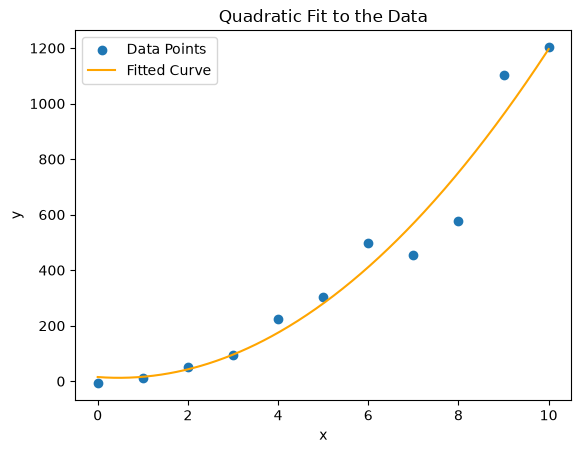

In [3]:

import matplotlib.pyplot as plt

x = data[:,0]
y = data[:,1]

# Create the design matrix for a quadratic model, which includes the squared term, the linear term, and the intercept
# x squared, x, and 1s for the intercept term
A = np.vstack((x**2, x, np.ones_like(x))).T
print(f"Matrix A for normal equations:\n{A}")

# Calculate the coefficients using OR 
coefficients = least_squares_QR(A, y)
print(f"\nCoefficients of fitted curve: {coefficients}")

# Create a range of x values for plotting the fitted curve
x_fit = np.linspace(min(x), max(x), 400)

# Calculate the corresponding y values from the coefficients
y_fit = coefficients[0] * x_fit**2 + coefficients[1] * x_fit + coefficients[2]

# Plot the original data points
plt.scatter(x, y, label='Data Points')
# Plot the fitted curve
plt.plot(x_fit, y_fit, color = 'orange', label='Fitted Curve')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Quadratic Fit to the Data')
plt.legend()
plt.show()

<h1>4.60</h1>


### a.

Given a matrix $A$ with n linearly independent eigenvectors $\mathbf{v}_1, \mathbf{v}_2, \ldots, \mathbf{v}_n$, and given any vector  $x$ as a linear combination of these eigenvectors:

$$x = \sum_{j=1}^n c_j\mathbf{v}_j$$

We use the fact that $A\mathbf{v}_j = \lambda_j\mathbf{v}_j$ to show that $A^kx = A^k \left(\sum_{j=1}^n c_j\mathbf{v}_j\right) = \sum_{j=1}^n c_j A^k \mathbf{v}_j = A^kx = \sum_{j=1}^n c_j\lambda_j^k\mathbf{v}_j$

### b. 

Assuming $\lambda_1$ is the dominant eigenvalue, we can factor out $\lambda_1^k$:

$$A^kx = \lambda_1^k \left( c_1\mathbf{v}_1 + c_2\left(\frac{\lambda_2}{\lambda_1}\right)^k\mathbf{v}_2 + \cdots + c_n\left(\frac{\lambda_n}{\lambda_1}\right)^k\mathbf{v}_n \right)$$

### c. 

If the eigenvalues are ordered such that $|\lambda_1| > |\lambda_2| \geq \ldots \geq |\lambda_n|$, then as $k$ approaches infinity, $\left(\frac{\lambda_i}{\lambda_1}\right)^k$ for $i > 1$ approaches zero, effectively eliminating the influence of the corresponding eigenvectors.

### d. 

The limit of the normalized vector $\frac{A^kx}{\lambda_1^k}$ as $k$ approaches infinity is:

$$\lim_{k \to \infty} \frac{A^kx}{\lambda_1^k} = c_1\mathbf{v}_1$$

This result illustrates that $A^kx$ becomes aligned with the dominant eigenvector $\mathbf{v}_1$ as $k$ grows large, provided that the initial vector $x$ has a non-zero component in the direction of $\mathbf{v}_1$.

This convergence is the basis of the power method for finding the dominant eigenvalue and eigenvector of a matrix.


<h1>4.61</h1>

In [4]:
def power_method(A, tol=1e-10, max_iter=1000, seed=2024):
    """Dominant eigenpair by the power method with a Rayleigh quotient."""
    A = np.asarray(A, dtype=float)
    n = A.shape[0]
    rng = np.random.default_rng(seed)
    x = rng.standard_normal(n)
    x /= np.linalg.norm(x)

    eigenvalue = 0.0
    for iteration in range(1, max_iter + 1):
        Ax = A @ x
        eigenvalue = x @ Ax
        residual = np.linalg.norm(Ax - eigenvalue * x)
        if residual < tol:
            break
        x = Ax / np.linalg.norm(Ax)
    return eigenvalue, x, iteration, residual


A = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 0]], dtype=float)
eigenvalue, eigenvector, iterations, residual = power_method(A)
print(f"dominant eigenvalue: {eigenvalue:.10f}")
print(f"eigenvector: {eigenvector}")
print(f"iterations: {iterations}, residual: {residual:.2e}")
print(f"numpy reference: {np.linalg.eigvals(A).real.max():.10f}")


dominant eigenvalue: 12.1228937846
eigenvector: [0.29982463 0.70747178 0.63999131]
iterations: 34, residual: 6.00e-11
numpy reference: 12.1228937846


In [5]:
A4 = np.array([[1, 2, 3, 4],
               [5, 6, 7, 8],
               [9, 0, 1, 2],
               [3, 4, 5, 6]], dtype=float)

eigenvalue, eigenvector, iterations, residual = power_method(A4)
print(f"dominant eigenvalue: {eigenvalue:.10f}")
print(f"iterations: {iterations}, residual: {residual:.2e}")
print(f"numpy reference: {np.linalg.eigvals(A4).real.max():.10f}")


dominant eigenvalue: 15.8167749046
iterations: 16, residual: 1.72e-11
numpy reference: 15.8167749045


In [6]:
def deflation_method(A, tol=1e-10, max_iter=2000, seed=2024):
    """First two eigenpairs of a symmetric matrix by projection deflation."""
    A = np.asarray(A, dtype=float)
    if not np.allclose(A, A.T):
        raise ValueError("this demonstration assumes a symmetric matrix")
    n = A.shape[0]

    first, v1, _, _ = power_method(A, tol=tol, max_iter=max_iter, seed=seed)
    projector = np.eye(n) - np.outer(v1, v1)
    deflated = projector @ A @ projector

    second, v2, _, _ = power_method(deflated, tol=tol, max_iter=max_iter, seed=seed + 1)
    return (first, v1), (second, v2)


S = np.array([[4, 1, 1],
              [1, 3, 0],
              [1, 0, 2]], dtype=float)
(first, v1), (second, v2) = deflation_method(S)
print(f"largest eigenvalue: {first:.10f}")
print(f"second eigenvalue:  {second:.10f}")
print(f"residual ||Sv1 - l1 v1||: {np.linalg.norm(S @ v1 - first * v1):.2e}")
print(f"residual ||Sv2 - l2 v2||: {np.linalg.norm(S @ v2 - second * v2):.2e}")
print(f"numpy reference: {np.linalg.eigvalsh(S)[::-1][:2]}")


largest eigenvalue: 4.8793852416
second eigenvalue:  2.6527036447
residual ||Sv1 - l1 v1||: 5.72e-11
residual ||Sv2 - l2 v2||: 8.85e-11
numpy reference: [4.87938524 2.65270364]


# QR ALgorithm

Let $A=A_0$, Find $Q_0 R_0 = A_0$. Then $A_1 = R_0 Q_0$

Notice $R_0 Q_0 = Q_0^{-1} Q_0 R_0 Q_0$ = $Q_0^{-1} A_0 Q_0$ has same eigenvalues as $A_0$

This iteration will usually converge to a triangular matrix

Can find all eigenvalues and eigenvectors but is not efficient.